Regional and segmental analysis

In [19]:
# install missing package(s) in the notebook environment
%pip install scikit-learn

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings("ignore")

root = Path(".").resolve()
processed = root / "data" / "processed"
out_ch = root / "outputs" / "charts"
out_tb = root / "outputs" / "tables"
out_ch.mkdir(parents=True, exist_ok=True)
out_tb.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi":150})
sns.set(style="whitegrid")



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
merged = pd.read_csv(processed/'merged_orders_details.csv',parse_dates=['order_date'])
print("merged shape:",merged.shape)
print(merged.columns.tolist())

merged shape: (1500, 10)
['order_id', 'order_date', 'customername', 'state', 'city', 'amount', 'profit', 'quantity', 'category', 'sub-category']


In [21]:
for col in ['order_id','order_date','amount','profit']:
    if col not in merged.columns:
        raise ValueError(f"Column {col} not found in merged DataFrame")
if 'customer_id' not in merged.columns:
    print("customer_id not found, creating from customer_name or order_id")
    if 'customer_name' in merged.columns:
        merged['customer_id'] = merged['customer_name'].astype('category').cat.codes
    else:
        merged['customer_id'] = merged['order_id'].astype('category').cat.codes

customer_id not found, creating from customer_name or order_id


In [22]:
snapshot_date = merged['order_date'].max() + pd.Timedelta(days=1)
rfm = merged.groupby('customer_id').agg(
    recency_days = ('order_date', lambda x: (snapshot_date - x.max()).days),
    frequency = ('order_id', 'nunique'),
    monetary = ('amount', 'sum')
).reset_index()

In [23]:
rfm = rfm[rfm['monetary'] > 0]  
rfm.describe().T.to_csv(out_tb / "rfm_describe.csv")

rfm['r_quartile'] = pd.qcut(rfm['recency_days'], 4, labels=[4,3,2,1]).astype(int)  
rfm['f_quartile'] = pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['m_quartile'] = pd.qcut(rfm['monetary'], 4, labels=[1,2,3,4]).astype(int)

rfm['rfm_score'] = rfm['r_quartile'].astype(int)*100 + rfm['f_quartile'].astype(int)*10 + rfm['m_quartile'].astype(int)
rfm['rfm_sum'] = rfm[['r_quartile','f_quartile','m_quartile']].sum(axis=1)

rfm.to_csv(out_tb / "rfm_scores.csv", index=False)
rfm.head()

,customer_id,recency_days,frequency,monetary,r_quartile,f_quartile,m_quartile,rfm_score,rfm_sum
0,0,365,1,1429,1,1,4,114,6
1,1,365,1,3889,1,1,4,114,6
2,2,363,1,2025,1,1,4,114,6
3,3,363,1,222,1,1,2,112,4
4,4,361,1,75,1,1,1,111,3


In [24]:
def label_segment(row):
    if row['rfm_sum'] >= 10:   
        return 'Champions'
    if row['rfm_sum'] >= 7:
        return 'Loyal'
    if row['rfm_sum'] >= 5:
        return 'Potential'
    return 'Needs Attention'

rfm['segment'] = rfm.apply(label_segment, axis=1)
rfm['segment'].value_counts().to_csv(out_tb / "rfm_segment_counts.csv")
rfm[['customer_id','recency_days','frequency','monetary','r_quartile','f_quartile','m_quartile','rfm_score','segment']].head()


,customer_id,recency_days,frequency,monetary,r_quartile,f_quartile,m_quartile,rfm_score,segment
0,0,365,1,1429,1,1,4,114,Potential
1,1,365,1,3889,1,1,4,114,Potential
2,2,363,1,2025,1,1,4,114,Potential
3,3,363,1,222,1,1,2,112,Needs Attention
4,4,361,1,75,1,1,1,111,Needs Attention


In [25]:

rfm_k = rfm[['customer_id','recency_days','frequency','monetary']].copy()
X = rfm_k[['recency_days','frequency','monetary']].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
kmeans.fit(X_scaled)
rfm_k['cluster'] = kmeans.labels_

rfm = rfm.merge(rfm_k[['customer_id','cluster']], on='customer_id', how='left')

cluster_summary = rfm.groupby('cluster').agg(
    customers=('customer_id','nunique'),
    avg_recency=('recency_days','mean'),
    avg_frequency=('frequency','mean'),
    avg_monetary=('monetary','mean'),
    avg_rfm_sum=('rfm_sum','mean')
).reset_index().sort_values('cluster')
cluster_summary.to_csv(out_tb / "rfm_kmeans_cluster_summary.csv", index=False)
cluster_summary


,cluster,customers,avg_recency,avg_frequency,avg_monetary,avg_rfm_sum
0,0,203,83.960591,1.0,286.512315,8.384236
1,1,176,282.971591,1.0,552.221591,4.954545
2,2,36,157.333333,1.0,3921.250000,9.111111
3,3,85,97.129412,1.0,1588.047059,10.000000


In [26]:

centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers, columns=['recency_days','frequency','monetary'])
centers_df['cluster'] = centers_df.index
centers_df.to_csv(out_tb / "kmeans_cluster_centers.csv", index=False)
centers_df


,recency_days,frequency,monetary,cluster
0,83.960591,1.0,286.512315,0
1,282.971591,1.0,552.221591,1
2,157.333333,1.0,3921.250000,2
3,97.129412,1.0,1588.047059,3


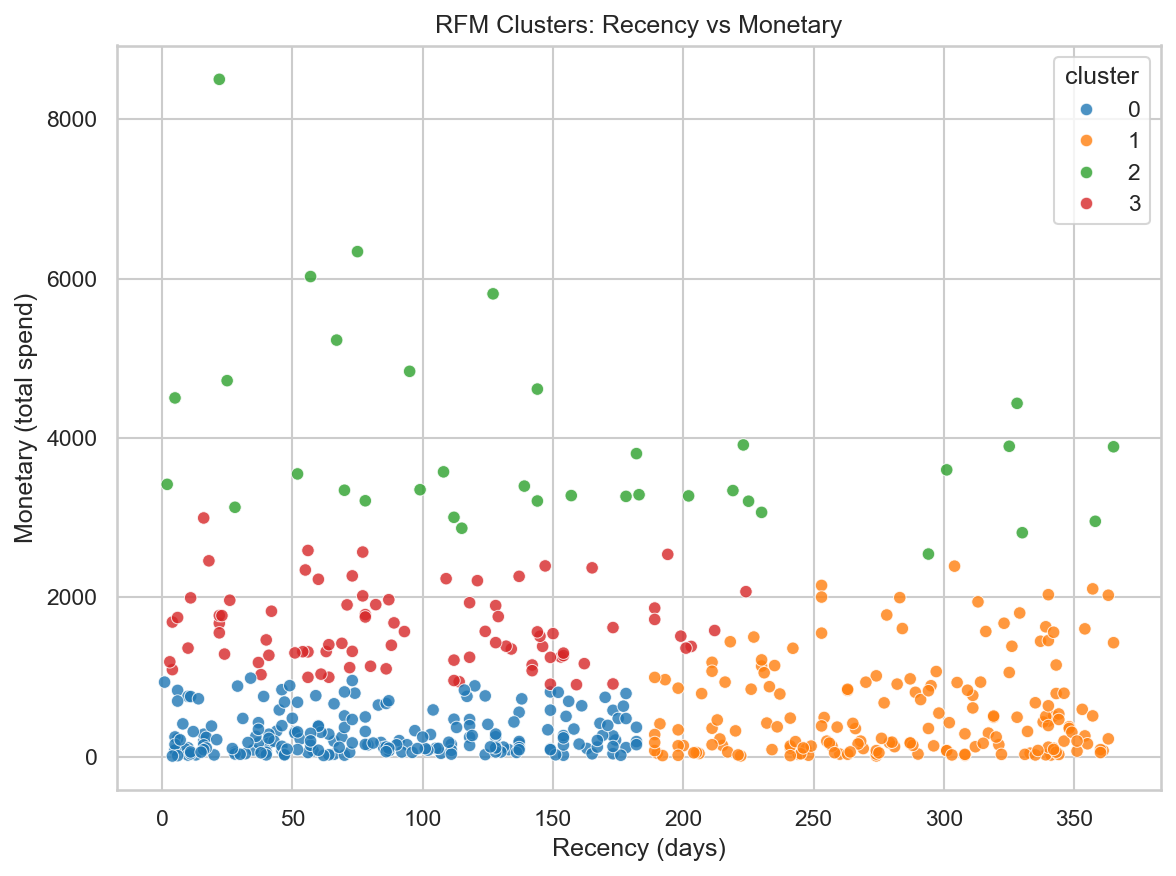

In [27]:

plot_sample = rfm.sample(min(len(rfm), 2000), random_state=1)
plt.figure(figsize=(8,6))
sns.scatterplot(data=plot_sample, x='recency_days', y='monetary', hue='cluster', palette='tab10', alpha=0.8)
plt.title("RFM Clusters: Recency vs Monetary")
plt.xlabel("Recency (days)")
plt.ylabel("Monetary (total spend)")
plt.legend(title='cluster')
plt.tight_layout()
plt.savefig(out_ch / "rfm_clusters_recency_monetary.png", dpi=300)
plt.show()


In [28]:

if 'unit_price' in merged.columns:
    merged['unit_price'] = pd.to_numeric(merged['unit_price'], errors='coerce').fillna(0)
elif 'price' in merged.columns:
    merged['unit_price'] = pd.to_numeric(merged['price'], errors='coerce').fillna(0)
else:
    if 'quantity' in merged.columns and merged['quantity'].sum()>0:
        merged['unit_price'] = merged['amount'] / merged['quantity'].replace({0:1})
    else:
        merged['unit_price'] = merged['amount']  

merged['price_band'] = pd.qcut(merged['unit_price'], 4, labels=['Low','Medium','High','Premium'])
price_band_summary = merged.groupby('price_band').agg(
    total_sales=('amount','sum'),
    total_profit=('profit','sum'),
    avg_margin_pct=('profit', lambda x: x.sum() / merged.loc[x.index,'amount'].sum() * 100 if merged.loc[x.index,'amount'].sum() != 0 else 0),
    avg_unit_price=('unit_price','mean')
).reset_index()
price_band_summary.to_csv(out_tb / "price_band_summary.csv", index=False)
price_band_summary


,price_band,total_sales,total_profit,avg_margin_pct,avg_unit_price
0,Low,13349,-728,-5.453592,9.715408
1,Medium,34203,760,2.222027,24.484422
2,High,81020,-1837,-2.267341,57.832604
3,Premium,302930,25760,8.503615,222.512975


In [29]:

if 'state' in merged.columns:
    state_map = merged.groupby('state').agg(
        total_sales=('amount','sum'),
        total_profit=('profit','sum'),
        order_count=('order_id','nunique'),
        avg_order_value=('amount','mean')
    ).reset_index().sort_values('total_sales', ascending=False)
    state_map.to_csv(out_tb / "state_map_for_dashboard.csv", index=False)
    state_map.head()
else:
    print("No 'state' column found. Please ensure state is present for choropleth mapping.")


In [30]:

possible_return_cols = [c for c in merged.columns if 'return' in c or 'refund' in c]
if possible_return_cols:
    rc = merged.groupby('order_month')[possible_return_cols].sum().reset_index()
    for col in possible_return_cols:
        rc[col + '_z'] = (rc[col] - rc[col].mean()) / rc[col].std()
    rc.to_csv(out_tb / "monthly_returns_anomalies.csv", index=False)
    display(rc.sort_values(possible_return_cols[0] + '_z', ascending=False).head(10))
else:
    print("No explicit returns/refund column found — skipping anomaly detection (you can add return/refund data and rerun).")


No explicit returns/refund column found — skipping anomaly detection (you can add return/refund data and rerun).


In [31]:

rfm.to_csv(out_tb / "rfm_enriched.csv", index=False)
merged.to_csv(processed / "merged_orders_enriched.csv", index=False)